# 1.Load the modules

In [1]:
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/gscdit/Breast-Cancer-Detection/refs/heads/master/data.csv')
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [3]:
df.columns

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='object')

In [4]:
df.drop(columns = ['id','Unnamed: 32'],inplace=True)

In [5]:
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [6]:
df.shape

(569, 31)

# 2.Train test split


In [7]:
x_train,x_test,y_train,y_test = train_test_split(df.iloc[:,1:], df.iloc[:,0], test_size=0.2)

In [8]:
x_train

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
370,16.350,23.29,109.00,840.4,0.09742,0.14970,0.18110,0.087730,0.2175,0.06218,...,19.380,31.03,129.30,1165.0,0.14150,0.46650,0.7087,0.22480,0.4824,0.09614
100,13.610,24.98,88.05,582.7,0.09488,0.08511,0.08625,0.044890,0.1609,0.05871,...,16.990,35.27,108.60,906.5,0.12650,0.19430,0.3169,0.11840,0.2651,0.07397
314,8.597,18.60,54.09,221.2,0.10740,0.05847,0.00000,0.000000,0.2163,0.07359,...,8.952,22.44,56.65,240.1,0.13470,0.07767,0.0000,0.00000,0.3142,0.08116
511,14.810,14.70,94.66,680.7,0.08472,0.05016,0.03416,0.025410,0.1659,0.05348,...,15.610,17.58,101.70,760.2,0.11390,0.10110,0.1101,0.07955,0.2334,0.06142
272,21.750,20.99,147.30,1491.0,0.09401,0.19610,0.21950,0.108800,0.1721,0.06194,...,28.190,28.18,195.90,2384.0,0.12720,0.47250,0.5807,0.18410,0.2833,0.08858
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
412,9.397,21.68,59.75,268.8,0.07969,0.06053,0.03735,0.005128,0.1274,0.06724,...,9.965,27.99,66.61,301.0,0.10860,0.18870,0.1868,0.02564,0.2376,0.09206
293,11.850,17.46,75.54,432.7,0.08372,0.05642,0.02688,0.022800,0.1875,0.05715,...,13.060,25.75,84.35,517.8,0.13690,0.17580,0.1316,0.09140,0.3101,0.07007
267,13.590,21.84,87.16,561.0,0.07956,0.08259,0.04072,0.021420,0.1635,0.05859,...,14.800,30.04,97.66,661.5,0.10050,0.17300,0.1453,0.06189,0.2446,0.07024
426,10.480,14.98,67.49,333.6,0.09816,0.10130,0.06335,0.022180,0.1925,0.06915,...,12.130,21.57,81.41,440.4,0.13270,0.29960,0.2939,0.09310,0.3020,0.09646


In [9]:
y_train

,diagnosis
370,M
100,M
314,B
511,B
272,M
...,...
412,B
293,B
267,B
426,B


# 3.Scaling the values

In [10]:
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)


In [11]:
x_train

array([[ 0.63603428,  0.92505715,  0.70904998, ...,  1.70254852,
         3.2055786 ,  0.7148319 ],
       [-0.14494736,  1.31323414, -0.15756262, ...,  0.07853318,
        -0.39138128, -0.53234402],
       [-1.57380173, -0.15219143, -1.56234371, ..., -1.72864178,
         0.42136943, -0.12786973],
       ...,
       [-0.15064796,  0.59200588, -0.19437814, ..., -0.78399602,
        -0.73071712, -0.7421756 ],
       [-1.03709063, -0.98367114, -1.00804257, ..., -0.30762836,
         0.21942323,  0.73283354],
       [ 0.04032201, -0.25095836, -0.02643317, ..., -0.57931514,
        -0.41621073, -0.37539224]])

In [12]:
x_test

array([[-0.38437239,  0.49323896, -0.40699813, ..., -1.00012438,
        -1.17268135, -0.82824592],
       [-0.19625272,  0.08438981, -0.24898094, ...,  0.04190125,
        -0.00569713, -0.54697035],
       [ 0.27404644,  1.48779894,  0.25402666, ...,  0.60053811,
        -0.38641539,  0.6158229 ],
       ...,
       [ 1.54812963,  2.18376125,  1.72664758, ...,  1.23396514,
        -0.11494672,  0.96010421],
       [-0.31881554,  0.58741207, -0.18031379, ...,  1.41559844,
         2.46731624,  1.33701348],
       [ 1.98707552,  1.67844208,  2.10307596, ...,  2.7022948 ,
         2.00383315,  2.52962194]])

# 4.Leable Encode the output column

In [13]:
lb = LabelEncoder()
y_train = lb.fit_transform(y_train)
y_test = lb.transform(y_test)

In [14]:
y_train

array([1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0,
       1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0,
       0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0,
       0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1,
       0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1,
       1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0,

# 5.convert numpy array to torch tensor

In [15]:
x_train_tensor = torch.from_numpy(x_train)
x_test_tensor = torch.from_numpy(x_test)
y_train_tensor = torch.from_numpy(y_train.astype('int64'))
y_test_tensor = torch.from_numpy(y_test.astype('int64'))

What happened

Your model’s predictions had shape (455, 1), one column of 455 probabilities. Your labels had shape (455,), a flat list of 455 values. When you multiply those two in PyTorch, it doesn’t raise an error. It “broadcasts” them into a 455×455 table so the shapes fit, comparing every prediction against every label instead of matching row 1 with row 1, row 2 with row 2, and so on.

A small example:

python
pred  = torch.tensor([[0.9], [0.1]])   # shape (2, 1)
label = torch.tensor([1., 0.])         # shape (2,)
(pred * label).shape                   # -> (2, 2), not (2,)

You wanted 2 comparisons and got 4.

Why it’s “silent”
No error message appeared.
The loss was still a normal-looking number.
The loss still went down over the epochs.

But the model was being rewarded for matching the average label across the whole dataset, not for getting each tumor right. So it learned “about 37% of tumors are malignant” instead of learning from the 30 features. The code ran, the loss fell, and the model was still wrong.

Why it’s a good lesson

It shows that a training loop can run without errors and still be broken. The habit it teaches is to print and check tensor shapes at each step (print(y_pred.shape, y.shape)), and to be suspicious if accuracy is oddly low.

One caution

That bullet in the post claims the bug happened to you. It did happen in your first notebook, and the current version still has it until you apply the .view(-1, 1) fix. So after you fix it and see accuracy jump, the line is honest, and it’s a strong story: “my accuracy was stuck at ~60%, I found the cause was a shape mismatch, and fixing it brought accuracy to ~97%.”

If you’d rather not mention it, you can swap the bullet for something simpler:

• How gradient descent, sigmoid, and binary cross-entropy work together, built entirely by hand


In [16]:
y_train_tensor = torch.from_numpy(y_train.astype('float64')).view(-1, 1)
y_test_tensor  = torch.from_numpy(y_test.astype('float64')).view(-1, 1)

In [17]:
x_train_tensor

tensor([[ 0.6360,  0.9251,  0.7090,  ...,  1.7025,  3.2056,  0.7148],
        [-0.1449,  1.3132, -0.1576,  ...,  0.0785, -0.3914, -0.5323],
        [-1.5738, -0.1522, -1.5623,  ..., -1.7286,  0.4214, -0.1279],
        ...,
        [-0.1506,  0.5920, -0.1944,  ..., -0.7840, -0.7307, -0.7422],
        [-1.0371, -0.9837, -1.0080,  ..., -0.3076,  0.2194,  0.7328],
        [ 0.0403, -0.2510, -0.0264,  ..., -0.5793, -0.4162, -0.3754]],
       dtype=torch.float64)

# 6.Defing a neural network


In [18]:
class mySimpleNN:

  def __init__(self, x):

    self.weights = torch.rand(x.shape[1], 1, dtype=torch.float64, requires_grad=True)
    self.bias = torch.zeros(1, dtype=torch.float64, requires_grad=True)

  def forword(self, x):
    z = torch.matmul(x, self.weights) + self.bias
    y_pred = torch.sigmoid(z)
    return y_pred

  def loss_function(self, y_pred, y):
    # Clamp predictions to avoid log(0)
    epsilon = 1e-7
    y_pred = torch.clamp(y_pred, epsilon, 1 - epsilon)

    # Calculate loss
    loss = -(y * torch.log(y_pred) + (1 - y) * torch.log(1 - y_pred)).mean()
    return loss

# 7.Dedining importeand Parameters

In [19]:
learning_rate = 0.1
epochs = 125

# 8.treaning pipeline

We turn off gradient tracking during the parameter update because updating the weights is a manual optimization step, not a part of your neural network's mathematical forward pass.
If you do not use torch.no_grad(), PyTorch will think the subtraction (model.weights - ...) is a new layer or operation in your neural network.
Here is exactly why that ruins your training loop:

1. It Explodes Memory (The Computational Graph Break)

PyTorch dynamically builds a computational graph to keep track of every mathematical operation so it can calculate gradients later.
• With torch.no_grad(): PyTorch simply changes the values of weights and bias in place and moves on.
• Without torch.no_grad(): PyTorch tracks the update itself. In the next epoch, it tracks the next update on top of that update. By epoch 100, you have a massive chain of 100 tracked updates stored in your RAM/VRAM, quickly causing an Out of Memory (OOM) error.

2. It Corrupts Your Gradient Calculations

If PyTorch tracks your parameter updates, the math behind loss.backward() gets contaminated. Instead of calculating the gradients of your model's layers, PyTorch will try to calculate the derivative of the optimizer's subtraction step itself, leading to wrong gradients or a runtime error.


In [20]:
# create a model
model = mySimpleNN(x_train_tensor)

loss_history = []
print(model.forword(x_train_tensor).shape, y_train_tensor.shape)

# define loop
for i in range(epochs):

  # forword pass
  y_pred = model.forword(x_train_tensor)

  # loss calculation
  loss = model.loss_function(y_pred, y_train_tensor)

  # backword pass
  loss.backward()

  # parameters update
  with torch.no_grad():
    model.weights -= learning_rate * model.weights.grad
    model.bias -= learning_rate * model.bias.grad

  # Zero gradients
  model.weights.grad.zero_()
  model.bias.grad.zero_()

  # print loss in each epoch
  print(f'Epoch: {i + 1}, Loss: {loss.item()}')

  loss_history.append(loss.item())

torch.Size([455, 1]) torch.Size([455, 1])
Epoch: 1, Loss: 0.5014990345007864
Epoch: 2, Loss: 0.4887959971471407
Epoch: 3, Loss: 0.4764922620269438
Epoch: 4, Loss: 0.4645733133634133
Epoch: 5, Loss: 0.453024777555863
Epoch: 6, Loss: 0.44183240695212034
Epoch: 7, Loss: 0.43098209287714767
Epoch: 8, Loss: 0.4204599030354409
Epoch: 9, Loss: 0.41025213656042725
Epoch: 10, Loss: 0.4003453903207927
Epoch: 11, Loss: 0.3907266302629152
Epoch: 12, Loss: 0.38138326220934987
Epoch: 13, Loss: 0.37230319832798736
Epoch: 14, Loss: 0.36347491582355884
Epoch: 15, Loss: 0.3548875062102928
Epoch: 16, Loss: 0.3465307145642664
Epoch: 17, Loss: 0.337801484923005
Epoch: 18, Loss: 0.3284877701311937
Epoch: 19, Loss: 0.3194053451357245
Epoch: 20, Loss: 0.3105461704127715
Epoch: 21, Loss: 0.30190311800797587
Epoch: 22, Loss: 0.2934699937798645
Epoch: 23, Loss: 0.2852415602095465
Epoch: 24, Loss: 0.2772135605800694
Epoch: 25, Loss: 0.26938274531649065
Epoch: 26, Loss: 0.26174689809876706
Epoch: 27, Loss: 0.25430

In [21]:
model.weights

tensor([[ 1.1168],
        [ 0.3185],
        [ 0.6552],
        [ 0.4045],
        [ 0.6239],
        [-0.2512],
        [ 0.5762],
        [ 0.3032],
        [ 0.5657],
        [-0.2066],
        [ 0.8339],
        [ 0.0494],
        [ 0.1044],
        [ 0.3045],
        [ 0.2200],
        [-0.5598],
        [-0.0476],
        [ 0.2563],
        [ 0.1983],
        [-0.1654],
        [ 1.1543],
        [ 0.9800],
        [ 0.3173],
        [ 0.6629],
        [ 0.4068],
        [ 0.3372],
        [ 0.6266],
        [ 0.7424],
        [ 0.2975],
        [ 0.0277]], dtype=torch.float64, requires_grad=True)

In [22]:
model.bias

tensor([-0.1583], dtype=torch.float64, requires_grad=True)

In [23]:
with torch.no_grad():
  y_pred = model.forword(x_test_tensor)

# 9.Calculating aaccrucy

In [24]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

# 1. Convert true labels to a flat NumPy array
y_true = y_test_tensor.detach().cpu().numpy().flatten()

# 2. Flatten your model predictions and convert to a NumPy array
y_pred_probs = y_pred.detach().cpu().numpy().flatten()

# 3. Apply the 0.5 threshold to convert probabilities to binary 0 or 1
y_pred_binary = (y_pred_probs >= 0.5).astype(int)

# 4. Calculate your metrics (y_true goes FIRST)
accuracy = accuracy_score(y_true, y_pred_binary)
precion = precision_score(y_true, y_pred_binary)
recall = recall_score(y_true, y_pred_binary)
f1 = f1_score(y_true, y_pred_binary)

print(f"Accuracy Score: {accuracy:.4f}")
print(f"precision_score: {precion:.4f}")
print(f"recall_score: {recall:.4f}")
print(f"f1_score: {f1:}")

Accuracy Score: 0.9649
precision_score: 0.9149
recall_score: 1.0000
f1_score: 0.9555555555555556


# 10.Loss curve

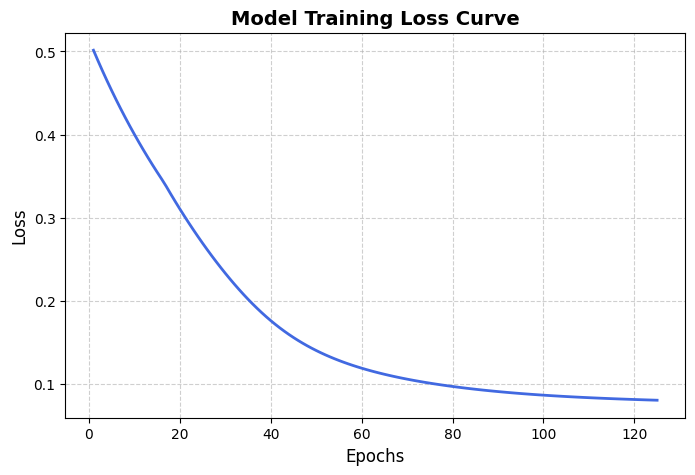

In [25]:
import matplotlib.pyplot as plt
# Plotting the loss history
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), loss_history, color='royalblue', linewidth=2)
plt.title('Model Training Loss Curve', fontsize=14, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

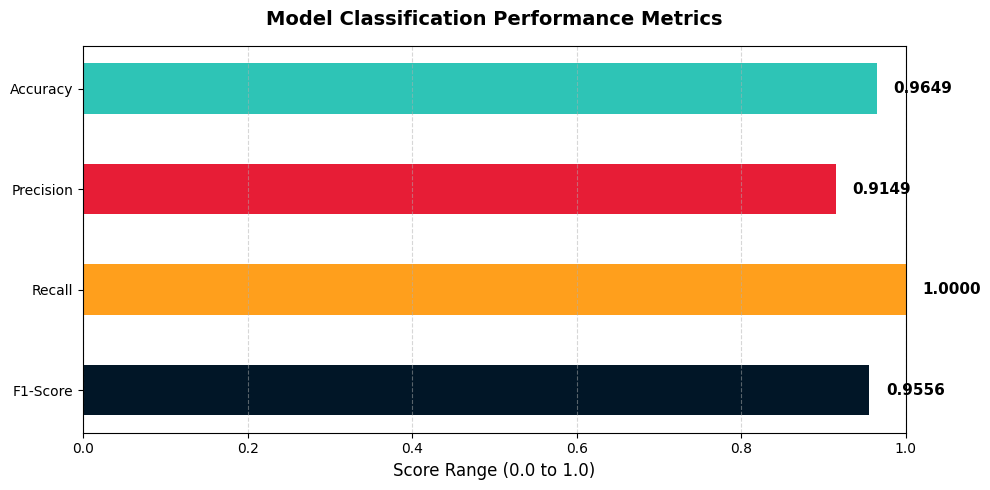

In [26]:
import matplotlib.pyplot as plt

# 1. Set up metrics data
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
metrics_values = [accuracy, precion, recall, f1]
colors = ['#2ec4b6', '#e71d36', '#ff9f1c', '#011627'] # High contrast palette

# 2. Build the horizontal bar plot
plt.figure(figsize=(10, 5))
bars = plt.barh(metrics_names, metrics_values, color=colors, height=0.5)

# 3. Style details
plt.title('Model Classification Performance Metrics', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Score Range (0.0 to 1.0)', fontsize=12)
plt.xlim(0.0, 1.0) # Keeps scale bounded between 0 and 1
plt.grid(axis='x', linestyle='--', alpha=0.5)

# 4. Add data value labels on top of each bar
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.02, bar.get_y() + bar.get_height()/2,
             f'{width:.4f}',
             va='center', ha='left', fontsize=11, fontweight='bold')

plt.gca().invert_yaxis() # Puts Accuracy at the top
plt.tight_layout()
plt.show()


In [27]:
y_pred.shape

torch.Size([114, 1])

In [28]:
y_train_tensor.shape

torch.Size([455, 1])

# 11. Using python nn modlue

In [30]:
import torch.nn as nn

In [48]:
class mySimpleNN(nn.Module):

  def __init__(self, x):

    super().__init__()
    self.linear = nn.Linear(x,1)
    self.sigmoid = nn.Sigmoid()

  def forward(self, x):

    out = self.linear(x)
    out = self.sigmoid(out)

    return out

  def loss_function(self, y_pred, y):
    # Clamp predictions to avoid log(0)
    epsilon = 1e-7
    y_pred = torch.clamp(y_pred, epsilon, 1 - epsilon)

    # Calculate loss
    loss = -(y * torch.log(y_pred) + (1 - y) * torch.log(1 - y_pred)).mean()
    return loss

In [51]:
# create a model
model = mySimpleNN(x_train_tensor.shape[1])

# define loop
for i in range(epochs):

  # forword pass
  y_pred = model(x_train_tensor.float())

  # loss calculation
  loss = model.loss_function(y_pred, y_train_tensor.float())

  # backword pass
  loss.backward()

  # parameters update
  with torch.no_grad():
    model.linear.weight -= learning_rate * model.linear.weight.grad
    model.linear.bias -= learning_rate * model.linear.bias.grad

  # Zero gradients
  model.linear.weight.grad.zero_()
  model.linear.bias.grad.zero_()

  # print loss in each epoch
  print(f'Epoch: {i + 1}, Loss: {loss.item()}')

  loss_history.append(loss.item())

Epoch: 1, Loss: 0.7624998688697815
Epoch: 2, Loss: 0.5902972221374512
Epoch: 3, Loss: 0.49442943930625916
Epoch: 4, Loss: 0.43340393900871277
Epoch: 5, Loss: 0.3905867040157318
Epoch: 6, Loss: 0.35850557684898376
Epoch: 7, Loss: 0.33333638310432434
Epoch: 8, Loss: 0.31291404366493225
Epoch: 9, Loss: 0.29591524600982666
Epoch: 10, Loss: 0.28148147463798523
Epoch: 11, Loss: 0.2690288722515106
Epoch: 12, Loss: 0.25814494490623474
Epoch: 13, Loss: 0.24852867424488068
Epoch: 14, Loss: 0.2399546205997467
Epoch: 15, Loss: 0.23225010931491852
Epoch: 16, Loss: 0.22528019547462463
Epoch: 17, Loss: 0.21893776953220367
Epoch: 18, Loss: 0.21313638985157013
Epoch: 19, Loss: 0.2078055888414383
Epoch: 20, Loss: 0.20288705825805664
Epoch: 21, Loss: 0.19833211600780487
Epoch: 22, Loss: 0.19409982860088348
Epoch: 23, Loss: 0.19015534222126007
Epoch: 24, Loss: 0.1864689141511917
Epoch: 25, Loss: 0.18301482498645782
Epoch: 26, Loss: 0.17977076768875122
Epoch: 27, Loss: 0.17671740055084229
Epoch: 28, Loss: 

In [72]:
with torch.no_grad():
  y_pred = model.forward(x_test_tensor.float())

In [68]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

# 1. Convert true labels to a flat NumPy array
y_true = y_test_tensor.detach().cpu().numpy().flatten()

# 2. Flatten your model predictions and convert to a NumPy array
y_pred_probs = y_pred.detach().cpu().numpy().flatten()

# 3. Apply the 0.5 threshold to convert probabilities to binary 0 or 1
y_pred_binary = (y_pred_probs >= 0.5).astype(int)

# 4. Calculate your metrics (y_true goes FIRST)
accuracy = accuracy_score(y_true, y_pred_binary)
precion = precision_score(y_true, y_pred_binary)
recall = recall_score(y_true, y_pred_binary)
f1 = f1_score(y_true, y_pred_binary)

print(f"Accuracy Score: {accuracy:.4f}")
print(f"precision_score: {precion:.4f}")
print(f"recall_score: {recall:.4f}")
print(f"f1_score: {f1:}")

Accuracy Score: 0.9737
precision_score: 0.9545
recall_score: 0.9767
f1_score: 0.9655172413793104


In [56]:
y_pred_binary.shape

(455,)

In [57]:
y_pred.shape

torch.Size([455, 1])

# 12.Further improving the code

In [63]:
class mySimpleNN(nn.Module):

  def __init__(self, x):

    super().__init__()
    self.linear = nn.Linear(x,1)
    self.sigmoid = nn.Sigmoid()

  def forward(self, x):

    out = self.linear(x)
    out = self.sigmoid(out)

    return out



In [64]:
loss_function = nn.BCELoss()

In [65]:
# create a model
model = mySimpleNN(x_train_tensor.shape[1])

# define loop
for i in range(epochs):

  # forword pass
  y_pred = model(x_train_tensor.float())

  # loss calculation
  loss = loss_function(y_pred, y_train_tensor.float())

  # backword pass
  loss.backward()

  # parameters update
  with torch.no_grad():
    model.linear.weight -= learning_rate * model.linear.weight.grad
    model.linear.bias -= learning_rate * model.linear.bias.grad

  # Zero gradients
  model.linear.weight.grad.zero_()
  model.linear.bias.grad.zero_()

  # print loss in each epoch
  print(f'Epoch: {i + 1}, Loss: {loss.item()}')

  loss_history.append(loss.item())

Epoch: 1, Loss: 0.5743926167488098
Epoch: 2, Loss: 0.4692799746990204
Epoch: 3, Loss: 0.40708619356155396
Epoch: 4, Loss: 0.3651716709136963
Epoch: 5, Loss: 0.33454450964927673
Epoch: 6, Loss: 0.3109360337257385
Epoch: 7, Loss: 0.292034387588501
Epoch: 8, Loss: 0.27646639943122864
Epoch: 9, Loss: 0.2633592188358307
Epoch: 10, Loss: 0.25212880969047546
Epoch: 11, Loss: 0.24236787855625153
Epoch: 12, Loss: 0.23378297686576843
Epoch: 13, Loss: 0.2261565774679184
Epoch: 14, Loss: 0.21932372450828552
Epoch: 15, Loss: 0.21315667033195496
Epoch: 16, Loss: 0.20755474269390106
Epoch: 17, Loss: 0.2024376094341278
Epoch: 18, Loss: 0.1977398842573166
Epoch: 19, Loss: 0.19340810179710388
Epoch: 20, Loss: 0.18939781188964844
Epoch: 21, Loss: 0.1856718510389328
Epoch: 22, Loss: 0.18219874799251556
Epoch: 23, Loss: 0.17895175516605377
Epoch: 24, Loss: 0.17590788006782532
Epoch: 25, Loss: 0.17304733395576477
Epoch: 26, Loss: 0.17035286128520966
Epoch: 27, Loss: 0.1678094118833542
Epoch: 28, Loss: 0.165

# 13. Using inbuild Optimizers

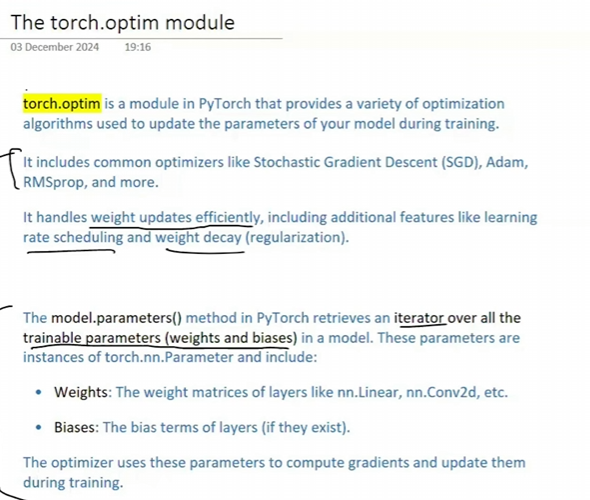

In [70]:
# create a model
model = mySimpleNN(x_train_tensor.shape[1])

optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
# define loop
for i in range(epochs):

  # forword pass
  y_pred = model(x_train_tensor.float())

  # loss calculation
  loss = loss_function(y_pred, y_train_tensor.float())

    # Zero gradients
  optimizer.zero_grad()

  # backword pass
  loss.backward()

  # parameters update
  optimizer.step()

  # print loss in each epoch
  print(f'Epoch: {i + 1}, Loss: {loss.item()}')

  loss_history.append(loss.item())

Epoch: 1, Loss: 0.5066429972648621
Epoch: 2, Loss: 0.4324488341808319
Epoch: 3, Loss: 0.38419702649116516
Epoch: 4, Loss: 0.34977999329566956
Epoch: 5, Loss: 0.32368630170822144
Epoch: 6, Loss: 0.30303335189819336
Epoch: 7, Loss: 0.2861584424972534
Epoch: 8, Loss: 0.27203017473220825
Epoch: 9, Loss: 0.25997212529182434
Epoch: 10, Loss: 0.2495206892490387
Epoch: 11, Loss: 0.2403462529182434
Epoch: 12, Loss: 0.23220722377300262
Epoch: 13, Loss: 0.2249220907688141
Epoch: 14, Loss: 0.21835140883922577
Epoch: 15, Loss: 0.21238590776920319
Epoch: 16, Loss: 0.2069387435913086
Epoch: 17, Loss: 0.2019396722316742
Epoch: 18, Loss: 0.1973312944173813
Epoch: 19, Loss: 0.1930660754442215
Epoch: 20, Loss: 0.18910428881645203
Epoch: 21, Loss: 0.18541240692138672
Epoch: 22, Loss: 0.18196190893650055
Epoch: 23, Loss: 0.17872834205627441
Epoch: 24, Loss: 0.17569060623645782
Epoch: 25, Loss: 0.17283035814762115
Epoch: 26, Loss: 0.17013157904148102
Epoch: 27, Loss: 0.16758020222187042
Epoch: 28, Loss: 0.1

In [73]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

# 1. Convert true labels to a flat NumPy array
y_true = y_test_tensor.detach().cpu().numpy().flatten()

# 2. Flatten your model predictions and convert to a NumPy array
y_pred_probs = y_pred.detach().cpu().numpy().flatten()

# 3. Apply the 0.5 threshold to convert probabilities to binary 0 or 1
y_pred_binary = (y_pred_probs >= 0.5).astype(int)

# 4. Calculate your metrics (y_true goes FIRST)
accuracy = accuracy_score(y_true, y_pred_binary)
precion = precision_score(y_true, y_pred_binary)
recall = recall_score(y_true, y_pred_binary)
f1 = f1_score(y_true, y_pred_binary)

print(f"Accuracy Score: {accuracy:.4f}")
print(f"precision_score: {precion:.4f}")
print(f"recall_score: {recall:.4f}")
print(f"f1_score: {f1:}")

Accuracy Score: 0.9561
precision_score: 0.9130
recall_score: 0.9767
f1_score: 0.9438202247191011
